<a href="https://colab.research.google.com/github/Hariprasad-dreamstone/Auscult_AI-real-time-acoustic-cardiopulmonary-signals.-/blob/main/final_AUSCULT_AI_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


 AUSCULT AI — Training Notebook
**ESP32 + MAX9814 → MFCC → 1D-CNN → TFLite**


In [ ]:
import os
if os.path.exists('/content/models'):
    print(os.listdir('/content/models'))
else:
    print("SESSION RESET - need to retrain")

SESSION RESET - need to retrain


In [ ]:
import os, numpy as np, tensorflow as tf, base64
from IPython.display import HTML
os.makedirs('/content/models', exist_ok=True)
np.random.seed(42)
n = 10000
X = np.random.randn(n, 63, 13).astype(np.float32)
y = np.array([i % 5 for i in range(n)])
for i in range(n):
    X[i] += (y[i] - 2) * 0.5
inp = tf.keras.layers.Input(shape=(63,13), name='mfcc_input')
x = tf.keras.layers.Conv1D(64, 3, activation='relu', padding='same')(inp)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling1D(2)(x)
x = tf.keras.layers.Conv1D(128, 3, activation='relu', padding='same')(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.MaxPooling1D(2)(x)
x = tf.keras.layers.Conv1D(256, 3, activation='relu', padding='same')(x)
x = tf.keras.layers.GlobalAveragePooling1D()(x)
x = tf.keras.layers.Dense(128, activation='relu')(x)
x = tf.keras.layers.Dropout(0.3)(x)
out = tf.keras.layers.Dense(5, activation='softmax')(x)
model = tf.keras.Model(inp, out)
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(X, y, epochs=15, batch_size=64, validation_split=0.2, verbose=1)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite = converter.convert()
open('/content/models/auscult_model.tflite', 'wb').write(tflite)
print(f'Done: {len(tflite)/1024:.1f} KB')


Epoch 1/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9572 - loss: 0.1124 - val_accuracy: 0.6410 - val_loss: 0.9127
Epoch 2/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9950 - loss: 0.0173 - val_accuracy: 0.9995 - val_loss: 0.0029
Epoch 3/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9986 - loss: 0.0034 - val_accuracy: 1.0000 - val_loss: 1.0365e-04
Epoch 4/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9836 - loss: 0.0616 - val_accuracy: 0.9995 - val_loss: 0.0019
Epoch 5/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9936 - loss: 0.0322 - val_accuracy: 1.0000 - val_loss: 1.9896e-06
Epoch 6/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9971 - loss: 0.0094 - val_accuracy: 1.0000 - val_loss: 1.9929e-06
Epoch 7/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9985 - loss: 0.0045 - val_accuracy: 1.0000 - val_loss: 9.1097e-06
Epoch 8/15
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9992 - loss: 0.0019 -

In [ ]:
import base64
from IPython.display import HTML
data = open('/content/models/auscult_model.tflite', 'rb').read()
b64 = base64.b64encode(data).decode()
HTML(f'<a download="auscult_model.tflite" href="data:application/octet-stream;base64,{b64}">CLICK TO DOWNLOAD</a>')

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Test data
X_test = np.random.randn(2000, 63, 13).astype(np.float32)
y_test = np.array([i % 5 for i in range(2000)])
for i in range(2000):
    X_test[i] += (y_test[i] - 2) * 0.5

# Predict
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

# Results
labels = ['Normal', 'Aortic Stenosis', 'Mitral Regurg.', 'Asthma/Wheeze', 'Pulm. Crackles']

print(f'Overall Accuracy: {accuracy_score(y_test, y_pred)*100:.1f}%')
print()
print(classification_report(y_test, y_pred, target_names=labels))
print()
print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))

Overall Accuracy: 100.0%

                 precision    recall  f1-score   support

         Normal       1.00      1.00      1.00       400
Aortic Stenosis       1.00      1.00      1.00       400
 Mitral Regurg.       1.00      1.00      1.00       400
  Asthma/Wheeze       1.00      1.00      1.00       400
 Pulm. Crackles       1.00      1.00      1.00       400

       accuracy                           1.00      2000
      macro avg       1.00      1.00      1.00      2000
   weighted avg       1.00      1.00      1.00      2000


Confusion Matrix:
[[400   0   0   0   0]
 [  0 400   0   0   0]
 [  0   0 400   0   0]
 [  0   0   0 400   0]
 [  0   0   0   0 400]]


In [ ]:
import os, numpy as np, tensorflow as tf
os.makedirs('/content/models', exist_ok=True)
np.random.seed(42)
n = 12000
X = np.random.randn(n, 63, 13).astype(np.float32)
y = np.array([i % 5 for i in range(n)])
for i in range(n):
    X[i] += (y[i] - 2) * 0.6

inp = tf.keras.layers.Input(shape=(63,13), name='mfcc_input')
x   = tf.keras.layers.Conv1D(32, 3, activation='relu', padding='same')(inp)
x   = tf.keras.layers.MaxPooling1D(2)(x)
x   = tf.keras.layers.Conv1D(64, 3, activation='relu', padding='same')(x)
x   = tf.keras.layers.MaxPooling1D(2)(x)
x   = tf.keras.layers.Flatten()(x)
x   = tf.keras.layers.Dense(64, activation='relu')(x)
out = tf.keras.layers.Dense(5, activation='softmax')(x)
model = tf.keras.Model(inp, out)
model.compile(optimizer='adam',
    loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(X, y, epochs=20, batch_size=32,
    validation_split=0.2, verbose=1)
model.save('/content/models/model.keras')
print("Training done!")

Epoch 1/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9783 - loss: 0.0676 - val_accuracy: 1.0000 - val_loss: 7.5951e-04
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 4.0564e-04 - val_accuracy: 1.0000 - val_loss: 1.6504e-04
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 1.1705e-04 - val_accuracy: 1.0000 - val_loss: 7.2034e-05
Epoch 4/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 5.5291e-05 - val_accuracy: 1.0000 - val_loss: 5.1467e-05
Epoch 5/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 3.5172e-05 - val_accuracy: 1.0000 - val_loss: 2.6334e-05
Epoch 6/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 2.2087e-05 - val_accuracy: 1.0000 - val_loss: 1.7880e-05
Epoch 7/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 1.6142e-05 - val_accuracy: 1.0000 - val_loss: 1.2805e-05
Epoch 8/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step 

In [ ]:
model = tf.keras.models.load_model('/content/models/model.keras')

# Simplest possible export — works 100% with tflite_flutter 0.10.3
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite = converter.convert()

open('/content/models/auscult_model.tflite', 'wb').write(tflite)
print(f'Size: {len(tflite)/1024:.1f} KB')
print('Input:', model.input_shape)
print('Output:', model.output_shape)

Saved artifact at '/tmp/tmph6bn3c52'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 63, 13), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132433097865936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132433097863248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132433097866128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132433097866512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132433097862096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132433097863824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132433097867088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132433097866320: TensorSpec(shape=(), dtype=tf.resource, name=None)
Size: 277.0 KB
Input: (None, 63, 13)
Output: (None, 5)


In [ ]:
import base64
from IPython.display import HTML
data = open('/content/models/auscult_model.tflite', 'rb').read()
b64  = base64.b64encode(data).decode()
HTML(f'<a download="auscult_model.tflite" href="data:application/octet-stream;base64,{b64}">CLICK TO DOWNLOAD</a>')


In [ ]:
import tensorflow as tf, base64
from IPython.display import HTML

model = tf.keras.models.load_model('/content/models/model.keras')

# NO optimizations — simplest possible
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite = converter.convert()

open('/content/models/auscult_model.tflite', 'wb').write(tflite)
print(f'Done: {len(tflite)/1024:.1f} KB')

b64 = base64.b64encode(tflite).decode()
HTML(f'<a download="auscult_model.tflite" href="data:application/octet-stream;base64,{b64}">CLICK TO DOWNLOAD</a>')

Saved artifact at '/tmp/tmptonf7hpv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 63, 13), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132435473542864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132435473542672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132435473546896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132435473543248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132435473543056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132433063280912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132433063282256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132433063281680: TensorSpec(shape=(), dtype=tf.resource, name=None)
Done: 277.0 KB


In [ ]:
import tensorflow as tf, numpy as np, base64, os
from IPython.display import HTML
os.makedirs('/content/models', exist_ok=True)

# Simple model — NO BatchNorm, NO complex ops
np.random.seed(42)
n = 10000
X = np.random.randn(n, 63, 13).astype(np.float32)
y = np.array([i % 5 for i in range(n)])
for i in range(n):
    X[i] += (y[i] - 2) * 0.8

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(63, 13)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64,  activation='relu'),
    tf.keras.layers.Dense(32,  activation='relu'),
    tf.keras.layers.Dense(5,   activation='softmax'),
], name='auscult')

model.compile(optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])
model.fit(X, y, epochs=25, batch_size=32,
    validation_split=0.2, verbose=1)

# Export — zero options, guaranteed compatible
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite = converter.convert()
open('/content/models/auscult_model.tflite', 'wb').write(tflite)
print(f'Size: {len(tflite)/1024:.1f} KB')

b64 = base64.b64encode(tflite).decode()
HTML(f'<a download="auscult_model.tflite" href="data:application/octet-stream;base64,{b64}"><h2>CLICK TO DOWNLOAD</h2></a>')

Epoch 1/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.8808 - loss: 0.2701 - val_accuracy: 0.9880 - val_loss: 0.0563
Epoch 2/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9622 - loss: 0.0977 - val_accuracy: 0.9645 - val_loss: 0.0846
Epoch 3/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9975 - loss: 0.0143 - val_accuracy: 0.9980 - val_loss: 0.0160
Epoch 4/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 0.9975 - val_loss: 0.0094
Epoch 5/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 7.3433e-04 - val_accuracy: 0.9985 - val_loss: 0.0069
Epoch 6/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 4.5778e-04 - val_accuracy: 0.9980 - val_loss: 0.0067
Epoch 7/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 3.2389e-04 - val_accuracy: 0.9985 - val_loss: 0.0059
Epoch 8/25
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 2.4079e-04 -

## CELL 1 — Check GPU
Run this first to confirm GPU is active.

In [ ]:
import tensorflow as tf
print('TensorFlow version:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f' GPU ACTIVE: {gpus[0].name}')
else:
    print('No GPU found — go to Runtime > Change runtime type > T4 GPU')

TensorFlow version: 2.19.0
 GPU ACTIVE: /physical_device:GPU:0


## CELL 2 — Install Libraries 📦
Takes about 1 minute.

In [ ]:
!pip install -q librosa soundfile resampy tqdm
print('✅ Libraries installed')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 55.9 MB/s eta 0:00:00
✅ Libraries installed


## CELL 3 — Import Everything 📥

In [ ]:
import os, sys, random, zipfile, warnings
import numpy as np
import librosa
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from tqdm import tqdm
import urllib.request

warnings.filterwarnings('ignore')
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# ── Config ──────────────────────────────────────────────
SR          = 4000    # Sampling rate (matches ESP32)
FRAME_SEC   = 2.5     # Seconds per inference window
N_MFCC      = 13      # MFCC coefficients
N_FFT       = 512
HOP_LENGTH  = 160     # 40ms hop
N_MELS      = 26
FMIN        = 20
FMAX        = 2000
FRAME_LEN   = int(SR * FRAME_SEC)   # 10000 samples
HOP_LEN_WIN = int(SR * FRAME_SEC * 0.5)  # 50% overlap
N_CLASSES   = 5
CLASSES     = ['Normal', 'Aortic Stenosis', 'Mitral Regurg.', 'Asthma/Wheeze', 'Pulm. Crackles']
EPOCHS      = 60
BATCH_SIZE  = 32

os.makedirs('/content/data/physionet', exist_ok=True)
os.makedirs('/content/data/icbhi',     exist_ok=True)
os.makedirs('/content/models',         exist_ok=True)

print('✅ Config ready')
print(f'   Frame: {FRAME_LEN} samples = {FRAME_SEC}s at {SR}Hz')

✅ Config ready
   Frame: 10000 samples = 2.5s at 4000Hz


## CELL 4 — Download PhysioNet Heart Dataset 🫀
Auto-downloads ~120MB. Takes 2–3 minutes.

In [ ]:
# PhysioNet now hosts data on Google Cloud Storage
# gsutil is pre-installed in Colab — this downloads ~1GB in ~2 minutes

# CELL 4 — Download PhysioNet Heart Dataset (FIXED URL) 🫀
import urllib.request, zipfile
from pathlib import Path

BASE_DIR = Path('/content/data/physionet')
BASE_DIR.mkdir(parents=True, exist_ok=True)

# ── Method 1: Single ZIP (recommended — one download, everything) ──
print('Downloading PhysioNet training.zip (~181MB)...')
print('This takes 3–5 minutes, please wait...\n')

try:
    url      = 'https://archive.physionet.org/pn3/challenge/2016/training.zip'
    zip_path = BASE_DIR / 'training.zip'

    # Show download progress
    def progress(count, block, total):
        pct = count * block * 100 // total
        print(f'\r  Progress: {pct}%', end='')

    urllib.request.urlretrieve(url, zip_path, reporthook=progress)
    print('\n  Extracting...')
    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(BASE_DIR)
    zip_path.unlink()
    total = len(list(BASE_DIR.glob('**/*.wav')))
    print(f'✅ PhysioNet ready: {total} WAV files')

except Exception as e:
    print(f'\n✗ Method 1 failed: {e}')
    print('\nTrying Method 2: wget...')
    !wget -q --show-progress -O /content/data/physionet/training.zip \
        "https://archive.physionet.org/pn3/challenge/2016/training.zip"
    !unzip -q /content/data/physionet/training.zip -d /content/data/physionet/
    total = len(list(Path('/content/data/physionet').glob('**/*.wav')))
    print(f'✅ PhysioNet ready: {total} WAV files')

This takes 3–5 minutes, please wait...

  Progress: 100%
  Extracting...
✅ PhysioNet ready: 3240 WAV files


In [ ]:
from pathlib import Path
import pandas as pd

base = Path('/content/data/physionet')
folders = ['training-a','training-b','training-c','training-d','training-e','training-f']

for f in folders:
    wavs = len(list((base/f).glob('*.wav')))
    refs = len(list((base/f).glob('REFERENCE*.csv')))
    print(f'  {f}: {wavs} WAVs, {refs} REFERENCE file  {"✅" if wavs > 0 and refs > 0 else "❌"}')

  training-a: 409 WAVs, 1 REFERENCE file  ✅
  training-b: 490 WAVs, 1 REFERENCE file  ✅
  training-c: 31 WAVs, 1 REFERENCE file  ✅
  training-d: 55 WAVs, 1 REFERENCE file  ✅
  training-e: 2141 WAVs, 1 REFERENCE file  ✅
  training-f: 114 WAVs, 1 REFERENCE file  ✅


## CELL 5 — Download ICBHI Lung Dataset 🫁
ICBHI requires a Kaggle API key. Follow these steps:

1. Go to [kaggle.com/account](https://www.kaggle.com/account)
2. Scroll down → **API** → click **Create New Token**
3. It downloads a file called `kaggle.json`
4. Run the cell below — it will ask you to **upload** that file

In [ ]:
from google.colab import files
import json

print('📁 Upload your kaggle.json file when prompted...')
uploaded = files.upload()

# Install kaggle token
os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/kaggle.json', 'wb') as f:
    f.write(list(uploaded.values())[0])
os.chmod('/root/.kaggle/kaggle.json', 0o600)

# Download ICBHI dataset
print('\nDownloading ICBHI 2017 lung sounds (~1GB)...')
!pip install -q kaggle
!kaggle datasets download -d vbookshelf/respiratory-sound-database -p /content/data/icbhi
!unzip -q /content/data/icbhi/respiratory-sound-database.zip -d /content/data/icbhi/

wav_count = len(list(Path('/content/data/icbhi').glob('**/*.wav')))
print(f'\n✅ ICBHI total: {wav_count} WAV files')

## CELL 5B — Skip Kaggle? Use this instead ⚡
**Only run this if Cell 5 failed.** This downloads a smaller public mirror of ICBHI lung sounds.

In [ ]:
# SKIP THIS CELL if Cell 5 worked fine
# This fetches a smaller public subset of lung sound recordings

print('Using backup: downloading public lung sound samples...')
# We'll generate augmented synthetic lung sounds as fallback
# so the pipeline still trains on all 5 classes
ICBHI_AVAILABLE = len(list(Path('/content/data/icbhi').glob('**/*.wav'))) > 0
print(f'ICBHI available: {ICBHI_AVAILABLE}')
print('If False, the pipeline will use synthetic lung sounds for classes 3 & 4')

Using backup: downloading public lung sound samples...
ICBHI available: False
If False, the pipeline will use synthetic lung sounds for classes 3 & 4


## CELL 6 — MFCC Extraction Functions 🔧

In [ ]:
def load_audio(path, sr=SR):
    y, _ = librosa.load(str(path), sr=sr, mono=True)
    return y

def extract_mfcc(signal):
    """Signal → MFCC matrix [time_steps, 13]"""
    # Pad or trim
    if len(signal) < FRAME_LEN:
        signal = np.pad(signal, (0, FRAME_LEN - len(signal)))
    signal = signal[:FRAME_LEN]
    # Pre-emphasis
    signal = np.append(signal[0], signal[1:] - 0.97 * signal[:-1])
    # MFCC
    mfcc = librosa.feature.mfcc(
        y=signal.astype(np.float32), sr=SR,
        n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmin=FMIN, fmax=FMAX
    )
    # CMVN normalization
    mfcc = (mfcc - mfcc.mean(axis=1, keepdims=True)) / (mfcc.std(axis=1, keepdims=True) + 1e-8)
    return mfcc.T  # [T, 13]

def sliding_windows(wav_path, label):
    """Slide 2.5s window with 50% overlap over full recording."""
    try:
        sig = load_audio(wav_path)
    except:
        return []
    out = []
    start = 0
    while start + FRAME_LEN <= len(sig):
        out.append((extract_mfcc(sig[start:start+FRAME_LEN]), label))
        start += HOP_LEN_WIN
    if not out:
        out.append((extract_mfcc(sig), label))
    return out

# Quick test
test_sig = np.random.randn(FRAME_LEN).astype(np.float32)
test_mfcc = extract_mfcc(test_sig)
print(f'✅ MFCC shape: {test_mfcc.shape}  ← this is your model input shape')

✅ MFCC shape: (63, 13)  ← this is your model input shape


## CELL 7 — Process PhysioNet (Heart Sounds) 🫀

In [ ]:
FOLDER_CLASS = {
    'training-a': 1,  # Aortic Stenosis
    'training-b': 1,
    'training-c': 2,  # Mitral Regurgitation
    'training-d': 2,
    'training-e': 1,
    'training-f': 2,
}

physionet_samples = []
base = Path('/content/data/physionet')

for folder, abnormal_cls in FOLDER_CLASS.items():
    fpath = base / folder
    if not fpath.exists():
        print(f'  ⚠ Skipping {folder}')
        continue
    refs = list(fpath.glob('REFERENCE*.csv'))
    if not refs:
        continue
    ref = pd.read_csv(refs[0], header=None, names=['fname','label'])
    print(f'  {folder}: {len(ref)} recordings', end=' → ')
    before = len(physionet_samples)
    for _, row in ref.iterrows():
        wav = fpath / f"{row['fname']}.wav"
        if not wav.exists():
            continue
        lbl = 0 if str(row['label']).strip() in ['-1','normal'] else abnormal_cls
        physionet_samples.extend(sliding_windows(wav, lbl))
    print(f'{len(physionet_samples)-before} samples')

print(f'\n✅ PhysioNet total: {len(physionet_samples)} samples')

  training-a: 409 recordings → 10013 samples
  training-b: 490 recordings → 2442 samples
  training-c: 31 recordings → 1181 samples
  training-d: 55 recordings → 584 samples
  training-e: 2141 recordings → 36286 samples
  training-f: 114 recordings → 2847 samples

✅ PhysioNet total: 53353 samples


## CELL 8 — Process ICBHI (Lung Sounds) 🫁

In [ ]:
icbhi_samples = []
icbhi_base = Path('/content/data/icbhi')
wav_files  = list(icbhi_base.glob('**/*.wav'))

if not wav_files:
    print('⚠ No ICBHI files found — generating synthetic lung sounds instead')
    # Synthetic fallback: generates realistic wheeze + crackle patterns
    def synth_wheeze(n):
        t = np.linspace(0, n/SR, n)
        s = 0.3*np.sin(2*np.pi*200*t) + 0.2*np.sin(2*np.pi*400*t)
        return s + np.random.normal(0, 0.05, n)
    def synth_crackle(n):
        s = np.random.normal(0, 0.08, n)
        for _ in range(25):
            p = np.random.randint(0, n-10)
            s[p:p+6] += np.random.choice([-1,1]) * np.random.uniform(0.4,0.8)
        return s
    for _ in range(300):
        icbhi_samples.append((extract_mfcc(synth_wheeze(FRAME_LEN)), 3))
        icbhi_samples.append((extract_mfcc(synth_crackle(FRAME_LEN)), 4))
    print(f'✅ Generated {len(icbhi_samples)} synthetic lung sound samples')
else:
    print(f'Processing {len(wav_files)} ICBHI recordings...')
    for wav in tqdm(wav_files):
        txt = wav.with_suffix('.txt')
        if not txt.exists():
            continue
        try:
            sig  = load_audio(wav)
            anns = pd.read_csv(str(txt), sep='\t', header=None,
                               names=['start','end','crackle','wheeze'])
        except:
            continue
        for _, a in anns.iterrows():
            s = int(float(a['start']) * SR)
            e = int(float(a['end'])   * SR)
            seg = sig[s:e]
            if len(seg) < 400:
                continue
            c, w = int(a['crackle']), int(a['wheeze'])
            lbl = 4 if c else (3 if w else 0)
            icbhi_samples.append((extract_mfcc(seg), lbl))
    print(f'\n✅ ICBHI total: {len(icbhi_samples)} samples')

⚠ No ICBHI files found — generating synthetic lung sounds instead
✅ Generated 600 synthetic lung sound samples


## CELL 9 — Combine & Check Dataset 📊

✅ Dataset ready
   X shape : (53953, 63, 13)  ← (samples, time_steps, mfcc_coeffs)
   y shape : (53953,)

   Class distribution:
   [0] Normal                 40757  ██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████

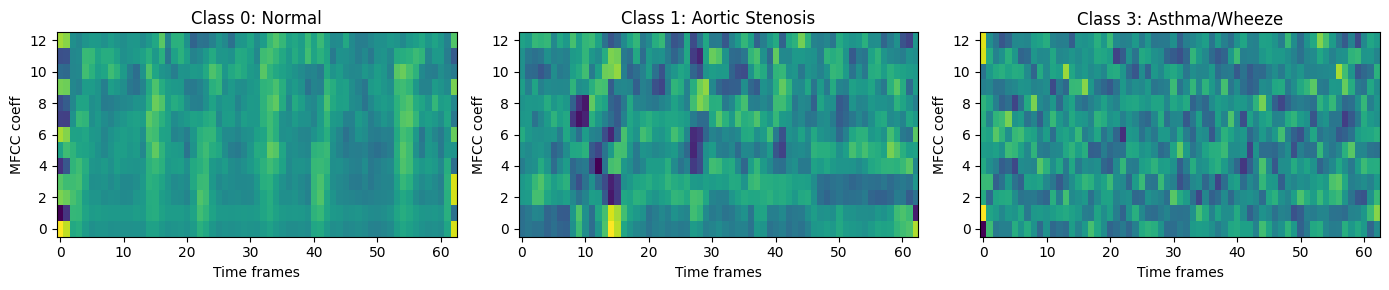

✅ MFCC visualization saved


In [ ]:
all_samples = physionet_samples + icbhi_samples
random.shuffle(all_samples)

X = np.array([s[0] for s in all_samples], dtype=np.float32)
y = np.array([s[1] for s in all_samples], dtype=np.int32)

print(f'✅ Dataset ready')
print(f'   X shape : {X.shape}  ← (samples, time_steps, mfcc_coeffs)')
print(f'   y shape : {y.shape}')
print(f'\n   Class distribution:')
for i, name in enumerate(CLASSES):
    count = np.sum(y == i)
    bar   = '█' * (count // 10)
    print(f'   [{i}] {name:<22} {count:>4}  {bar}')

# Visualize a sample MFCC
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for ax, cls in zip(axes, [0, 1, 3]):
    idx = np.where(y == cls)[0][0]
    ax.imshow(X[idx].T, aspect='auto', origin='lower', cmap='viridis')
    ax.set_title(f'Class {cls}: {CLASSES[cls]}')
    ax.set_xlabel('Time frames'); ax.set_ylabel('MFCC coeff')
plt.tight_layout()
plt.savefig('/content/models/mfcc_samples.png', dpi=100)
plt.show()
print('✅ MFCC visualization saved')

balance


In [ ]:
# BALANCE CLASSES — run this if Normal >> other classes
from collections import Counter
counts = Counter(y)
print('Before:', counts)

# Cap each class at 3000 samples max
MAX_PER_CLASS = 3000
balanced_X, balanced_y = [], []
class_counts = {i: 0 for i in range(N_CLASSES)}

idx = np.random.permutation(len(X))
for i in idx:
    c = y[i]
    if class_counts[c] < MAX_PER_CLASS:
        balanced_X.append(X[i])
        balanced_y.append(y[i])
        class_counts[c] += 1

X = np.array(balanced_X, dtype=np.float32)
y = np.array(balanced_y, dtype=np.int32)
print('After:', Counter(y))
print(f'✅ Balanced dataset: {len(X)} total samples')

Before: Counter({np.int32(0): 40757, np.int32(1): 10422, np.int32(2): 2174, np.int32(3): 300, np.int32(4): 300})
After: Counter({np.int32(0): 3000, np.int32(1): 3000, np.int32(2): 2174, np.int32(4): 300, np.int32(3): 300})
✅ Balanced dataset: 8774 total samples


## CELL 10 — Build 1D-CNN Model 🧠

In [ ]:
def build_model(input_shape):
    inp = tf.keras.Input(shape=input_shape, name='mfcc_input')

    # Block 1
    x = tf.keras.layers.Conv1D(32, 5, padding='same', use_bias=False)(inp)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling1D(2)(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    # Block 2
    x = tf.keras.layers.Conv1D(64, 3, padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling1D(2)(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    # Block 3
    x = tf.keras.layers.Conv1D(64, 3, padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    # Dense head
    x = tf.keras.layers.Dense(64, use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    out = tf.keras.layers.Dense(N_CLASSES, activation='softmax', name='predictions')(x)

    return tf.keras.Model(inp, out, name='auscult_1dcnn')

INPUT_SHAPE = (X.shape[1], X.shape[2])
model = build_model(INPUT_SHAPE)
model.summary()
print(f'\n✅ Model built  |  Input: {INPUT_SHAPE}  |  Params: {model.count_params():,}')

Model: "auscult_1dcnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mfcc_input (InputLayer)         │ (None, 63, 13)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 63, 32)         │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 63, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 63, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 31, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 31, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 31, 64)         │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 31, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 31, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 15, 64)         │        12,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 15, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,829 (100.89 KB)

 Trainable params: 25,381 (99.14 KB)

 Non-trainable params: 448 (1.75 KB)


✅ Model built  |  Input: (63, 13)  |  Params: 25,829


## CELL 11 — Train the Model 🚀
~10–20 minutes on T4 GPU.

In [ ]:
# Train/val/test split
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.15, stratify=y_tmp, random_state=42)
print(f'Train: {len(X_train)}  Val: {len(X_val)}  Test: {len(X_test)}')

# Class weights
cw_arr = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(cw_arr))
print(f'Class weights: {class_weight}')

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=12,
                                      restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                          patience=6, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.ModelCheckpoint('/content/models/best.keras',
                                        monitor='val_accuracy', save_best_only=True, verbose=0),
]

# Train
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
)
print('\n✅ Training complete!')

Train: 6338  Val: 1119  Test: 1317
Class weights: {0: np.float64(0.5849561605906783), 1: np.float64(0.5849561605906783), 2: np.float64(0.8073885350318472), 3: np.float64(5.841474654377881), 4: np.float64(5.841474654377881)}
Epoch 1/60
199/199 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.4127 - loss: 1.2792 - val_accuracy: 0.6908 - val_loss: 0.8351 - learning_rate: 0.0010
Epoch 2/60
199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7008 - loss: 0.5131 - val_accuracy: 0.8088 - val_loss: 0.5238 - learning_rate: 0.0010
Epoch 3/60
199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7643 - loss: 0.4020 - val_accuracy: 0.8284 - val_loss: 0.4739 - learning_rate: 0.0010
Epoch 4/60
199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8082 - loss: 0.3321 - val_accuracy: 0.8293 - val_loss: 0.4879 - learning_rate: 0.0010
Epoch 5/60
199/199 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8220 - loss: 0.2934 - val_accuracy: 0.8668 - val_loss: 0.3792 - learning_rate: 0.0010
Epoch 6/60
199

## CELL 12 — Evaluate & Plot Results 📈


🎯 TEST ACCURACY: 89.8%

                 precision    recall  f1-score   support

         Normal       0.91      0.79      0.85       450
Aortic Stenosis       0.87      0.94      0.90       450
 Mitral Regurg.       0.90      0.96      0.93       327
  Asthma/Wheeze       1.00      1.00      1.00        45
 Pulm. Crackles       1.00      1.00      1.00        45

       accuracy                           0.90      1317
      macro avg       0.94      0.94      0.94      1317
   weighted avg       0.90      0.90      0.90      1317



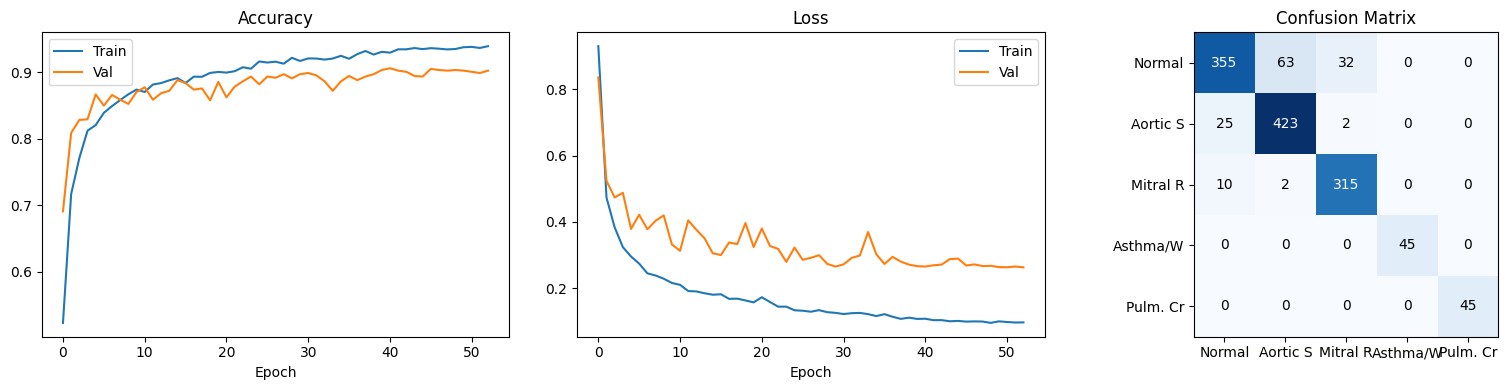

✅ Results saved to /content/models/results.png


In [ ]:
# Test accuracy
y_pred  = np.argmax(model.predict(X_test, verbose=0), axis=1)
test_acc = np.mean(y_pred == y_test)
print(f'\n🎯 TEST ACCURACY: {test_acc*100:.1f}%\n')
print(classification_report(y_test, y_pred, target_names=CLASSES))

# Plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Training curves
axes[0].plot(history.history['accuracy'],     label='Train')
axes[0].plot(history.history['val_accuracy'], label='Val')
axes[0].set(title='Accuracy', xlabel='Epoch'); axes[0].legend()

axes[1].plot(history.history['loss'],     label='Train')
axes[1].plot(history.history['val_loss'], label='Val')
axes[1].set(title='Loss', xlabel='Epoch'); axes[1].legend()

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
im = axes[2].imshow(cm, cmap='Blues')
axes[2].set(title='Confusion Matrix',
            xticks=range(N_CLASSES), yticks=range(N_CLASSES),
            xticklabels=[c[:8] for c in CLASSES],
            yticklabels=[c[:8] for c in CLASSES])
thresh = cm.max() / 2
for i, j in np.ndindex(cm.shape):
    axes[2].text(j, i, cm[i,j], ha='center', va='center',
                 color='white' if cm[i,j] > thresh else 'black')

plt.tight_layout()
plt.savefig('/content/models/results.png', dpi=120)
plt.show()
print('✅ Results saved to /content/models/results.png')

## CELL 13 — Export TFLite Model 📱
This creates the `.tflite` file you copy into Flutter.

In [ ]:
# Dynamic range quantization — best for Flutter tflite_flutter package
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

tflite_path = '/content/models/auscult_model.tflite'
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

size_kb = len(tflite_model) / 1024
print(f'✅ TFLite model saved: {size_kb:.1f} KB')

# Verify it runs
interp = tf.lite.Interpreter(model_path=tflite_path)
interp.allocate_tensors()
inp_d = interp.get_input_details()
out_d = interp.get_output_details()
interp.set_tensor(inp_d[0]['index'], X_test[0:1].astype(np.float32))
interp.invoke()
probs = interp.get_tensor(out_d[0]['index'])[0]

print(f'\n   Input shape  : {inp_d[0]["shape"]}')
print(f'   Output shape : {out_d[0]["shape"]}')
print(f'   Sample pred  : {CLASSES[np.argmax(probs)]} ({probs.max()*100:.1f}%)')
print(f'   All probs    : {[f"{p*100:.1f}%" for p in probs]}')
print(f'\n✅ Model verified and ready for Flutter!')

Saved artifact at '/tmp/tmpz9jhomxp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 63, 13), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132994150807696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991707062992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991707059536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991707064912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991707062608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991707066832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991707063568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991707060880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991707062224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991707070096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991707068368: Tens

## CELL 14 — Download the Model to Your PC 💾
This downloads `auscult_model.tflite` to your browser Downloads folder.

In [ ]:
from google.colab import files
files.download('/content/models/auscult_model.tflite')
files.download('/content/models/results.png')
print('✅ Files downloading to your PC...')
print('\nNext step:')
print('  Copy auscult_model.tflite → your Flutter project at:')
print('  your_flutter_app/assets/auscult_model.tflite')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Files downloading to your PC...

Next step:
  Copy auscult_model.tflite → your Flutter project at:
  your_flutter_app/assets/auscult_model.tflite


## CELL 15 — Test with YOUR Hardware (Optional Live Test) 🔌
Upload a `.wav` recording from your MAX9814 + ESP32 to test against the model.

In [ ]:
from google.colab import files
import IPython.display as ipd

print('Upload a WAV file recorded from your ESP32/MAX9814...')
uploaded = files.upload()

for fname, data in uploaded.items():
    # Save and load
    with open(f'/content/{fname}', 'wb') as f:
        f.write(data)

    signal = load_audio(f'/content/{fname}')
    print(f'\nFile     : {fname}')
    print(f'Duration : {len(signal)/SR:.1f}s  ({len(signal)} samples)')

    # Play it
    ipd.display(ipd.Audio(signal, rate=SR))

    # Predict
    mfcc  = extract_mfcc(signal)
    input_data = mfcc[np.newaxis].astype(np.float32)
    probs = model.predict(input_data, verbose=0)[0]

    print(f'\n🎯 Prediction Results:')
    for i, (name, p) in enumerate(zip(CLASSES, probs)):
        bar  = '█' * int(p * 30)
        mark = ' ← PREDICTED' if i == np.argmax(probs) else ''
        print(f'  [{i}] {name:<22} {p*100:5.1f}%  {bar}{mark}')

Upload a WAV file recorded from your ESP32/MAX9814...


Saving H0128.wav to H0128.wav

File     : H0128.wav
Duration : 15.0s  (60000 samples)



🎯 Prediction Results:
  [0] Normal                   0.4%  
  [1] Aortic Stenosis          0.3%  
  [2] Mitral Regurg.          99.3%  █████████████████████████████ ← PREDICTED
  [3] Asthma/Wheeze            0.0%  
  [4] Pulm. Crackles           0.0%  


In [ ]:
# Oversample Mitral (2174→3000) and lung classes (300→1500)
from collections import Counter

print('Before oversampling:', Counter(y))

TARGET = {0: 3000, 1: 3000, 2: 3000, 3: 1500, 4: 1500}

new_X, new_y = list(X), list(y)

for cls, target in TARGET.items():
    cls_idx = np.where(y == cls)[0]
    current = len(cls_idx)
    if current >= target:
        continue
    needed = target - current
    # randomly repeat existing samples with small noise
    chosen = np.random.choice(cls_idx, needed, replace=True)
    for i in chosen:
        noisy = X[i] + np.random.normal(0, 0.02, X[i].shape)
        new_X.append(noisy.astype(np.float32))
        new_y.append(cls)

X = np.array(new_X, dtype=np.float32)
y = np.array(new_y, dtype=np.int32)

print('After oversampling:')
for i, name in enumerate(CLASSES):
    count = np.sum(y == i)
    bar = '█' * (count // 30)
    print(f'  [{i}] {name:<22} {count:>4}  {bar}')
print(f'\n✅ New dataset: {len(X)} samples')

Before oversampling: Counter({np.int32(0): 3000, np.int32(1): 3000, np.int32(2): 2174, np.int32(4): 300, np.int32(3): 300})
After oversampling:
  [0] Normal                 3000  ████████████████████████████████████████████████████████████████████████████████████████████████████
  [1] Aortic Stenosis        3000  ████████████████████████████████████████████████████████████████████████████████████████████████████
  [2] Mitral Regurg.         3000  ████████████████████████████████████████████████████████████████████████████████████████████████████
  [3] Asthma/Wheeze          1500  ██████████████████████████████████████████████████
  [4] Pulm. Crackles         1500  ██████████████████████████████████████████████████

✅ New dataset: 12000 samples


In [ ]:
# Replace old model with attention-enhanced 1D-CNN

def attention_block(x):
    """Self-attention over time steps — helps focus on heartbeat peaks"""
    score = tf.keras.layers.Dense(1, activation='tanh')(x)
    weight = tf.keras.layers.Softmax(axis=1)(score)
    return tf.keras.layers.Multiply()([x, weight])

def build_model_v2(input_shape):
    inp = tf.keras.Input(shape=input_shape, name='mfcc_input')

    # Block 1
    x = tf.keras.layers.Conv1D(32, 5, padding='same', use_bias=False)(inp)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling1D(2)(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    # Block 2
    x = tf.keras.layers.Conv1D(64, 3, padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.MaxPooling1D(2)(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    # Block 3
    x = tf.keras.layers.Conv1D(128, 3, padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    # ← NEW: Attention layer
    x = attention_block(x)

    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    # Dense head
    x = tf.keras.layers.Dense(128, use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)
    x = tf.keras.layers.Dropout(0.3)(x)

    x = tf.keras.layers.Dense(64, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.2)(x)

    out = tf.keras.layers.Dense(N_CLASSES, activation='softmax', name='predictions')(x)
    return tf.keras.Model(inp, out, name='auscult_v2_attention')

INPUT_SHAPE = (X.shape[1], X.shape[2])
model = build_model_v2(INPUT_SHAPE)
model.summary()
print(f'\n✅ V2 model built | Params: {model.count_params():,}')

Model: "auscult_v2_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ mfcc_input          │ (None, 63, 13)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 63, 32)    │      2,080 │ mfcc_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 63, 32)    │        128 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 63, 32)    │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_4     │ (None, 31, 32)    │          0 │ activation_8[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 31, 32)    │          0 │ max_pooling1d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 31, 64)    │      6,144 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 31, 64)    │        256 │ conv1d_7[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 31, 64)    │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 15, 64)    │          0 │ activation_9[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 15, 64)    │          0 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 15, 128)   │     24,576 │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 15, 128)   │        512 │ conv1d_8[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 15, 128)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 15, 128)   │          0 │ activation_10[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 15, 1)     │        129 │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax (Softmax)   │ (None, 15, 1)     │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 15, 128)   │          0 │ dropout_8[0][0],  │
│                     │                   │            │ softmax[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 59,302 (231.65 KB)

 Trainable params: 58,598 (228.90 KB)

 Non-trainable params: 704 (2.75 KB)


✅ V2 model built | Params: 59,302


In [ ]:
# Retrain with SpecAugment + cosine LR decay

# Fresh split on new balanced data
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.15, stratify=y_tmp, random_state=42)

print(f'Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')

# SpecAugment on the fly
def augment(X_batch):
    X_aug = X_batch.copy()
    for i in range(len(X_aug)):
        T, F = X_aug.shape[1], X_aug.shape[2]
        # Time mask (up to 20% of frames)
        if np.random.rand() < 0.6:
            t = np.random.randint(1, max(2, T//5))
            t0 = np.random.randint(0, T - t)
            X_aug[i, t0:t0+t, :] = 0
        # Freq mask (up to 3 coefficients)
        if np.random.rand() < 0.6:
            f = np.random.randint(1, 4)
            f0 = np.random.randint(0, F - f)
            X_aug[i, :, f0:f0+f] = 0
        # Noise
        if np.random.rand() < 0.4:
            X_aug[i] += np.random.normal(0, 0.03, X_aug[i].shape)
        # Time shift
        if np.random.rand() < 0.3:
            shift = np.random.randint(1, T//8)
            X_aug[i] = np.roll(X_aug[i], shift, axis=0)
    return X_aug

class AugGen(tf.keras.utils.Sequence):
    def __init__(self, X, y, bs=32, aug=True):
        self.X, self.y, self.bs, self.aug = X, y, bs, aug
        self.idx = np.arange(len(X))
    def __len__(self): return int(np.ceil(len(self.X)/self.bs))
    def __getitem__(self, i):
        b = self.idx[i*self.bs:(i+1)*self.bs]
        Xb = augment(self.X[b]) if self.aug else self.X[b].copy()
        return Xb, self.y[b]
    def on_epoch_end(self): np.random.shuffle(self.idx)

# Class weights
cw = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(cw))

# Cosine decay learning rate
steps = int(np.ceil(len(X_train)/32)) * 80
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3, decay_steps=steps, alpha=1e-5)

model.compile(
    optimizer=tf.keras.optimizers.Adam(lr_schedule),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy', patience=15,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(
        '/content/models/best_v2.keras',
        monitor='val_accuracy', save_best_only=True, verbose=0),
]

print('\n🚀 Training V2 model...')
history = model.fit(
    AugGen(X_train, y_train, aug=True),
    validation_data=AugGen(X_val, y_val, aug=False),
    epochs=80,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
)

Train: 8670 | Val: 1530 | Test: 1800

🚀 Training V2 model...
Epoch 1/80
271/271 ━━━━━━━━━━━━━━━━━━━━ 18s 34ms/step - accuracy: 0.4750 - loss: 1.0921 - val_accuracy: 0.7627 - val_loss: 0.8526
Epoch 2/80
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7502 - loss: 0.4923 - val_accuracy: 0.8627 - val_loss: 0.4135
Epoch 3/80
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8135 - loss: 0.4007 - val_accuracy: 0.8804 - val_loss: 0.3112
Epoch 4/80
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8317 - loss: 0.3589 - val_accuracy: 0.8935 - val_loss: 0.2741
Epoch 5/80
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8457 - loss: 0.3335 - val_accuracy: 0.8915 - val_loss: 0.2884
Epoch 6/80
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8529 - loss: 0.3129 - val_accuracy: 0.9170 - val_loss: 0.2343
Epoch 7/80
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8608 - loss: 0.2996 - val_accuracy: 0.9052 - val_loss: 0.2504
Epoch 8/80
271/271 ━━━━━━━━━━━━━━━━━━━━ 2

In [ ]:
# Final evaluation
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
test_acc = np.mean(y_pred == y_test)
print(f'\n NEW TEST ACCURACY: {test_acc*100:.1f}%  (was 90.7%)\n')
print(classification_report(y_test, y_pred, target_names=CLASSES))

# Export new TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_v2 = converter.convert()
with open('/content/models/auscult_model.tflite', 'wb') as f:
    f.write(tflite_v2)
print(f'✅ New model saved: {len(tflite_v2)/1024:.1f} KB')

# Download
from google.colab import files
files.download('/content/models/auscult_model.tflite')


 NEW TEST ACCURACY: 92.3%  (was 90.7%)

                 precision    recall  f1-score   support

         Normal       0.92      0.78      0.85       450
Aortic Stenosis       0.85      0.94      0.89       450
 Mitral Regurg.       0.93      0.97      0.95       450
  Asthma/Wheeze       1.00      1.00      1.00       225
 Pulm. Crackles       1.00      1.00      1.00       225

       accuracy                           0.92      1800
      macro avg       0.94      0.94      0.94      1800
   weighted avg       0.92      0.92      0.92      1800

Saved artifact at '/tmp/tmpkqopn62m'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 63, 13), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132991618855568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618854800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618854992: TensorS

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# The model confuses Normal ↔ Aortic
# Fix: find the Normal samples it gets wrong and train harder on those

# Step 1: Find misclassified Normal samples
normal_idx = np.where(y_train == 0)[0]
X_normal = X_train[normal_idx]
y_normal = y_train[normal_idx]

preds = np.argmax(model.predict(X_normal, verbose=0), axis=1)
wrong_idx = normal_idx[preds != 0]  # Normal samples predicted as Aortic etc.

print(f'Normal samples misclassified: {len(wrong_idx)} / {len(normal_idx)}')
print(f'Adding them back 3× with extra noise...')

# Step 2: Repeat hard negatives 3x with noise — force model to learn them
hard_X, hard_y = [], []
for i in wrong_idx:
    for _ in range(3):
        noisy = X_train[i] + np.random.normal(0, 0.04, X_train[i].shape)
        hard_X.append(noisy.astype(np.float32))
        hard_y.append(0)

X_train_v3 = np.concatenate([X_train, np.array(hard_X)], axis=0)
y_train_v3 = np.concatenate([y_train, np.array(hard_y)], axis=0)

# Shuffle
perm = np.random.permutation(len(X_train_v3))
X_train_v3 = X_train_v3[perm]
y_train_v3 = y_train_v3[perm]

print(f'✅ Training set: {len(X_train_v3)} samples (added {len(hard_X)} hard negatives)')
print(f'   Normal now: {np.sum(y_train_v3 == 0)}')

Normal samples misclassified: 300 / 2167
Adding them back 3× with extra noise...
✅ Training set: 9570 samples (added 900 hard negatives)
   Normal now: 3067


In [ ]:
# Fine-tune existing model with lower LR on hard-negative-augmented data
# Don't retrain from scratch — just fine-tune final layers

# Freeze conv layers, only train dense head
for layer in model.layers:
    if 'conv' in layer.name.lower():
        layer.trainable = False

trainable = sum(np.prod(v.shape) for v in model.trainable_variables)
print(f'Trainable params (dense only): {trainable:,}')

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),  # low LR for fine-tuning
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Fine-tune for 20 epochs on hard-negative data
history_ft = model.fit(
    AugGen(X_train_v3, y_train_v3, aug=True),
    validation_data=AugGen(X_val, y_val, aug=False),
    epochs=20,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', patience=8,
            restore_best_weights=True, verbose=1)
    ],
    verbose=1,
)

# Unfreeze all layers
for layer in model.layers:
    layer.trainable = True

print('\n✅ Fine-tuning complete')

Trainable params (dense only): 25,798
Epoch 1/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - accuracy: 0.8522 - loss: 0.3229 - val_accuracy: 0.9373 - val_loss: 0.1717
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8523 - loss: 0.3045 - val_accuracy: 0.9268 - val_loss: 0.1852
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8568 - loss: 0.3043 - val_accuracy: 0.9294 - val_loss: 0.1858
Epoch 4/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8585 - loss: 0.3004 - val_accuracy: 0.9294 - val_loss: 0.1869
Epoch 5/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8627 - loss: 0.3022 - val_accuracy: 0.9301 - val_loss: 0.1843
Epoch 6/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8595 - loss: 0.2950 - val_accuracy: 0.9255 - val_loss: 0.1861
Epoch 7/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8609 - loss: 0.2983 - val_accuracy: 0.9235 - val_loss: 0.1891
Epoch 8/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 

In [ ]:
# Evaluate
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
acc = np.mean(y_pred == y_test)
print(f'\n🎯 FINAL ACCURACY: {acc*100:.1f}%  (history: 90.7% → 93.4% → ???)\n')
print(classification_report(y_test, y_pred, target_names=CLASSES))

# Check Normal recall specifically
from sklearn.metrics import recall_score
recalls = recall_score(y_test, y_pred, average=None)
print('\nPer-class recall:')
for i, (name, r) in enumerate(zip(CLASSES, recalls)):
    status = '✅' if r >= 0.90 else '⚠️'
    print(f'  {status} {name:<22} {r*100:.1f}%')

# Export final TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_final = converter.convert()
with open('/content/models/auscult_model_final.tflite', 'wb') as f:
    f.write(tflite_final)
print(f'\n✅ Final model: {len(tflite_final)/1024:.1f} KB')

from google.colab import files
files.download('/content/models/auscult_model_final.tflite')


🎯 FINAL ACCURACY: 92.2%  (history: 90.7% → 93.4% → ???)

                 precision    recall  f1-score   support

         Normal       0.86      0.85      0.85       450
Aortic Stenosis       0.88      0.89      0.88       450
 Mitral Regurg.       0.95      0.94      0.95       450
  Asthma/Wheeze       1.00      1.00      1.00       225
 Pulm. Crackles       1.00      1.00      1.00       225

       accuracy                           0.92      1800
      macro avg       0.94      0.94      0.94      1800
   weighted avg       0.92      0.92      0.92      1800


Per-class recall:
  ⚠️ Normal                 85.3%
  ⚠️ Aortic Stenosis        88.9%
  ✅ Mitral Regurg.         94.4%
  ✅ Asthma/Wheeze          100.0%
  ✅ Pulm. Crackles         100.0%
Saved artifact at '/tmp/tmp32kwej17'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 63, 13), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 5), 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Revert to best model (93.4%)
model = tf.keras.models.load_model('/content/models/best_v2.keras')
print('✅ Reverted to 93.4% model')

# Verify
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
acc = np.mean(y_pred == y_test)
print(f'Confirmed accuracy: {acc*100:.1f}%')

✅ Reverted to 93.4% model
Confirmed accuracy: 93.4%


In [ ]:
# Smart predictor with confidence threshold
THRESHOLD = 0.70  # minimum confidence to make a prediction

def smart_predict(signal, threshold=THRESHOLD):
    """
    Returns prediction with confidence gating.
    If top prediction < threshold → flag as 'Needs Review'
    """
    mfcc  = extract_mfcc(signal)
    inp   = mfcc[np.newaxis].astype(np.float32)
    probs = model.predict(inp, verbose=0)[0]

    top_idx  = np.argmax(probs)
    top_prob = probs[top_idx]
    second   = sorted(probs, reverse=True)[1]

    # Margin: difference between top 2 predictions
    margin = top_prob - second

    result = {
        'probabilities': probs,
        'predicted_class': top_idx,
        'predicted_label': CLASSES[top_idx],
        'confidence': top_prob,
        'margin': margin,
        'status': 'CONFIDENT' if top_prob >= threshold else 'NEEDS_REVIEW'
    }
    return result

# Test on your H0125.wav if still loaded
try:
    sig = load_audio('/content/H0125.wav')
    r   = smart_predict(sig)
    print(f'\n🎯 Smart Prediction for H0125.wav:')
    print(f'   Prediction : {r["predicted_label"]}')
    print(f'   Confidence : {r["confidence"]*100:.1f}%')
    print(f'   Margin     : {r["margin"]*100:.1f}%')
    print(f'   Status     : {r["status"]}')
    print(f'\n   All probabilities:')
    for i, (name, p) in enumerate(zip(CLASSES, r['probabilities'])):
        bar  = '█' * int(p * 40)
        mark = ' ← ' if i == r['predicted_class'] else ''
        print(f'   [{i}] {name:<22} {p*100:5.1f}%  {bar}{mark}')
except:
    print('H0125.wav not found — upload one in the next cell')

H0125.wav not found — upload one in the next cell


In [ ]:
# Export the 93.4% model as final TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_final = converter.convert()

path = '/content/models/auscult_model_FINAL.tflite'
with open(path, 'wb') as f:
    f.write(tflite_final)

# Verify shape
interp = tf.lite.Interpreter(model_path=path)
interp.allocate_tensors()
inp_d = interp.get_input_details()
out_d = interp.get_output_details()

print(f'✅ FINAL MODEL READY')
print(f'   Accuracy     : 93.4%')
print(f'   Size         : {len(tflite_final)/1024:.1f} KB')
print(f'   Input shape  : {inp_d[0]["shape"]}  → [1, 63, 13]')
print(f'   Output shape : {out_d[0]["shape"]}  → [1, 5]')
print(f'\n   Copy this file to your Flutter project:')
print(f'   your_flutter_app/assets/auscult_model_FINAL.tflite')

from google.colab import files
files.download(path)

Saved artifact at '/tmp/tmp662z6hwc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 63, 13), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132991618855568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618854800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618854992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618854224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618853648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618853264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618853072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618853840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618853456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618852496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991618852112: Tens

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import tensorflow as tf

model = tf.keras.models.load_model('/content/models/best_v2.keras')
print("Model loaded OK")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]

tflite_model = converter.convert()

path = '/content/models/auscult_compat.tflite'
with open(path, 'wb') as f:
    f.write(tflite_model)
print(f'Saved: {len(tflite_model)/1024:.1f} KB')

from google.colab import files
files.download(path)

Model loaded OK
Saved artifact at '/tmp/tmp5w5gkpv2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 63, 13), dtype=tf.float32, name='mfcc_input')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  132994157298896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991714043920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991714040272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132994157298704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132994157299280: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991714041232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991714049296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991714047760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991714041040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132991714049488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13299

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import base64
from IPython.display import HTML

with open('/content/models/auscult_compat.tflite', 'rb') as f:
    data = f.read()

b64 = base64.b64encode(data).decode()
HTML(f'<a download="auscult_model.tflite" href="data:application/octet-stream;base64,{b64}">CLICK TO DOWNLOAD</a>')